In [1]:
%matplotlib inline
import scrublet as scr
import scipy.io
import matplotlib.pyplot as plt
import numpy as np
import os

In [3]:
#Load data
input_dir = '../rna_d3/outs/filtered_feature_bc_matrix/'
counts_matrix = scipy.io.mmread(input_dir + 'matrix.mtx.gz').T.tocsc()
genes = np.array(scr.load_genes('permissionFiles/features_d3_genes.tsv', delimiter='\t', column=1))
# print(counts_matrix)
print('Counts matrix shape: {} rows, {} columns'.format(counts_matrix.shape[0], counts_matrix.shape[1]))
print('Number of genes in gene list: {}'.format(len(genes)))

Counts matrix shape: 8734 rows, 31053 columns
Number of genes in gene list: 31053


In [4]:
# calculate
scrub = scr.Scrublet(counts_matrix, expected_doublet_rate=0.06)

In [5]:
doublet_scores, predicted_doublets = scrub.scrub_doublets(min_counts=2, 
                                                          min_cells=3, 
                                                          min_gene_variability_pctl=85, 
                                                          n_prin_comps=30)

Preprocessing...
Simulating doublets...
Embedding transcriptomes using PCA...
Calculating doublet scores...
Automatically set threshold at doublet score = 0.29
Detected doublet rate = 1.7%
Estimated detectable doublet fraction = 23.4%
Overall doublet rate:
	Expected   = 6.0%
	Estimated  = 7.4%
Elapsed time: 28.3 seconds


(<Figure size 576x216 with 2 Axes>,
 array([<matplotlib.axes._subplots.AxesSubplot object at 0x7f9b03ff3790>,
       dtype=object))

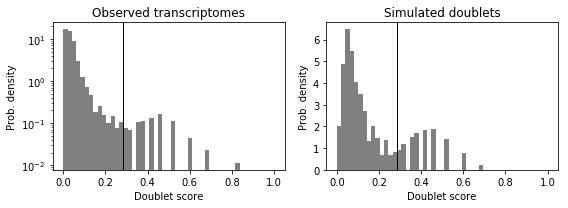

In [6]:
# plot
scrub.plot_histogram()

In [7]:
# cluster view
print('Running UMAP...')
scrub.set_embedding('UMAP', scr.get_umap(scrub.manifold_obs_, 10, min_dist=0.3))

# # Uncomment to run tSNE - slow
# print('Running tSNE...')
# scrub.set_embedding('tSNE', scr.get_tsne(scrub.manifold_obs_, angle=0.9))

# # Uncomment to run force layout - slow
# print('Running ForceAtlas2...')
# scrub.set_embedding('FA', scr.get_force_layout(scrub.manifold_obs_, n_neighbors=5. n_iter=1000))
    
print('Done.')

Running UMAP...


/home/yi/.pyenv/versions/anaconda3-2019.07/lib/python3.7/site-packages/numba/compiler.py:602: NumbaPerformanceWarning: 
The keyword argument 'parallel=True' was specified but no transformation for parallel execution was possible.

To find out why, try turning on parallel diagnostics, see http://numba.pydata.org/numba-doc/latest/user/parallel.html#diagnostics for help.

File "../../.pyenv/versions/anaconda3-2019.07/lib/python3.7/site-packages/umap/rp_tree.py", line 135:
@numba.njit(fastmath=True, nogil=True, parallel=True)
def euclidean_random_projection_split(data, indices, rng_state):
^

  self.func_ir.loc))
/home/yi/.pyenv/versions/anaconda3-2019.07/lib/python3.7/site-packages/umap/nndescent.py:92: NumbaPerformanceWarning: 
The keyword argument 'parallel=True' was specified but no transformation for parallel execution was possible.

To find out why, try turning on parallel diagnostics, see http://numba.pydata.org/numba-doc/latest/user/parallel.html#diagnostics for help.

File "../../

Done.


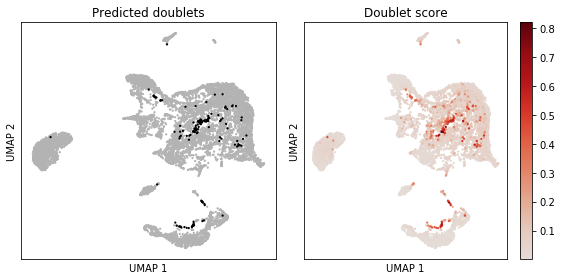

In [10]:
scrub.plot_embedding('UMAP', order_points=True);

# scrub.plot_embedding('tSNE', order_points=True);
# scrub.plot_embedding('FA', order_points=True);

In [37]:
# use mitochondria deleted data, unnormalized

import pandas as pd
d3mt = pd.read_csv('d3mt.csv')

In [38]:
d3mt

,Unnamed: 0,AAACCCAAGAAGTGTT,AAACCCAAGAATAGTC,AAACCCAAGATTAGCA,AAACCCAAGGATTACA,AAACCCAAGTACCATC,AAACCCACAAGAGGTC,AAACCCACATGTAACC,AAACCCACATGTGTCA,AAACCCAGTAACCAGG,...,TTTGGTTTCACAAGGG,TTTGTTGCATCATTTC,TTTGTTGGTCCGACGT,TTTGTTGGTTAAGTCC,TTTGTTGGTTGTTTGG,TTTGTTGTCAAGGAGC,TTTGTTGTCACCGCTT,TTTGTTGTCATTGGTG,TTTGTTGTCGATACAC,TTTGTTGTCGTGGGAA
0,Mrpl15,1,0,8,0,1,0,0,0,4,...,0,0,4,1,4,0,0,1,0,0
1,Lypla1,0,0,0,0,0,0,0,0,0,...,0,1,0,0,0,0,0,1,2,0
2,Gm37988,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
3,Tcea1,0,0,4,1,0,4,1,0,6,...,2,0,0,0,1,0,1,0,1,0
4,Atp6v1h,0,0,1,0,0,0,0,0,1,...,0,0,1,0,2,0,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
16427,AC168977.2,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
16428,AC168977.1,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
16429,AC149090.1,0,0,2,3,1,0,0,0,1,...,0,0,3,0,4,0,0,1,0,1
16430,CAAA01118383.1,0,0,1,1,0,0,0,0,0,...,0,0,1,1,2,0,0,0,0,0


In [39]:
scrub = scr.Scrublet(scipy.sparse.csr_matrix(d3mt.iloc[:,1:].values.T), expected_doublet_rate=0.06)

In [40]:
doublet_scores, predicted_doublets = scrub.scrub_doublets(min_counts=2, 
                                                          min_cells=3, 
                                                          min_gene_variability_pctl=85, 
                                                          n_prin_comps=30)

Preprocessing...
Simulating doublets...
Embedding transcriptomes using PCA...
Calculating doublet scores...
Automatically set threshold at doublet score = 0.30
Detected doublet rate = 1.7%
Estimated detectable doublet fraction = 24.5%
Overall doublet rate:
	Expected   = 6.0%
	Estimated  = 6.9%
Elapsed time: 16.9 seconds


(<Figure size 576x216 with 2 Axes>,
 array([<matplotlib.axes._subplots.AxesSubplot object at 0x7f9af85f8ed0>,
       dtype=object))

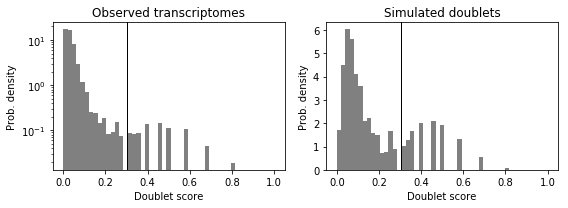

In [41]:
scrub.plot_histogram()

Running UMAP...


/home/yi/.pyenv/versions/anaconda3-2019.07/lib/python3.7/site-packages/numba/compiler.py:602: NumbaPerformanceWarning: 
The keyword argument 'parallel=True' was specified but no transformation for parallel execution was possible.

To find out why, try turning on parallel diagnostics, see http://numba.pydata.org/numba-doc/latest/user/parallel.html#diagnostics for help.

File "../../.pyenv/versions/anaconda3-2019.07/lib/python3.7/site-packages/umap/nndescent.py", line 47:
    @numba.njit(parallel=True)
    def nn_descent(
    ^

  self.func_ir.loc))


Done.


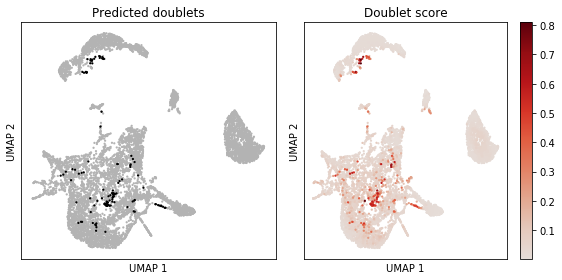

In [42]:
# cluster view
print('Running UMAP...')
scrub.set_embedding('UMAP', scr.get_umap(scrub.manifold_obs_, 10, min_dist=0.3))
print('Done.')
scrub.plot_embedding('UMAP', order_points=True);

In [51]:
df = pd.DataFrame({
    'barcodes': d3mt.columns[1:],
    'doublet_score': scrub.doublet_scores_obs_,
    'predicted_doublet': scrub.predicted_doublets_
})


df.to_csv('scrublet_d3.csv', index=False)

In [49]:
df

,barcodes,doublet_score,predicted_doublet
0,AAACCCAAGAAGTGTT,0.013399,False
1,AAACCCAAGAATAGTC,0.012027,False
2,AAACCCAAGATTAGCA,0.027539,False
3,AAACCCAAGGATTACA,0.043832,False
4,AAACCCAAGTACCATC,0.019233,False
...,...,...,...
7772,TTTGTTGTCAAGGAGC,0.019233,False
7773,TTTGTTGTCACCGCTT,0.678082,True
7774,TTTGTTGTCATTGGTG,0.012475,False
7775,TTTGTTGTCGATACAC,0.034719,False
